<a href="https://colab.research.google.com/github/hfmq27ccfk-bot/26FW/blob/main/ossPython10_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Fashion MNIST 데이터셋 로드 및 전처리
# 60,000개의 학습 데이터와 10,000개의 테스트 데이터로 구성된 의류 이미지 데이터셋입니다.
fashion_mnist = tf.keras.datasets.fashion_mnist
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# 픽셀 값(0~255)을 0~1 사이의 범위로 정규화(Normalization)합니다.
x_train, x_test = x_train / 255.0, x_test / 255.0

print(f"학습 데이터 형태: {x_train.shape}")
print(f"테스트 데이터 형태: {x_test.shape}")

# 클래스 이름 정의 (0~9까지의 라벨 매칭)
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


# 2. 신경망 모델 구축 (Sequential API 사용)
model = models.Sequential([
    # 28x28 2차원 이미지를 1차원(784개)으로 펼침
    layers.Flatten(input_shape=(28, 28)),

    # 은닉층: 128개의 뉴런, 활성화 함수로 ReLU 사용
    layers.Dense(128, activation='relu'),

    # 드롭아웃(Dropout): 과적합(Overfitting) 방지하기 위해 20%의 뉴런을 무작위로 끔
    layers.Dropout(0.2),

    # 출력층: 10개의 의류 품목을 분류해야 하므로 10개의 뉴런, softmax 활성화 함수 사용
    layers.Dense(10, activation='softmax')
])


# 3. 모델 컴파일 (손실 함수, 옵티마이저, 평가지표 설정)
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# 모델 구조 요약 확인
model.summary()


# 4. 모델 학습
print("\n--- 모델 학습 시작 ---")
history = model.fit(x_train, y_train, epochs=5, validation_split=0.2)


# 5. 모델 평가 (테스트 데이터를 이용한 성능 측정)
print("\n--- 모델 평가 ---")
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f"\n테스트 정확도: {test_acc * 100:.2f}%")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
학습 데이터 형태: (60000, 28, 28)
테스트 데이터 형태: (10000, 28, 28)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)


--- 모델 학습 시작 ---
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8050 - loss: 0.5517 - val_accuracy: 0.8469 - val_loss: 0.4314
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8516 - loss: 0.4099 - val_accuracy: 0.8662 - val_loss: 0.3718
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8642 - loss: 0.3732 - val_accuracy: 0.8633 - val_loss: 0.3682
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8718 - loss: 0.3521 - val_accuracy: 0.8596 - val_loss: 0.3754
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8753 - loss: 0.3348 - val_accuracy: 0.8774 - val_loss: 0.3406

--- 모델 평가 ---
313/313 - 1s - 4ms/step - accuracy: 0.8698 - loss: 0.3607

테스트 정확도: 86.98%


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step


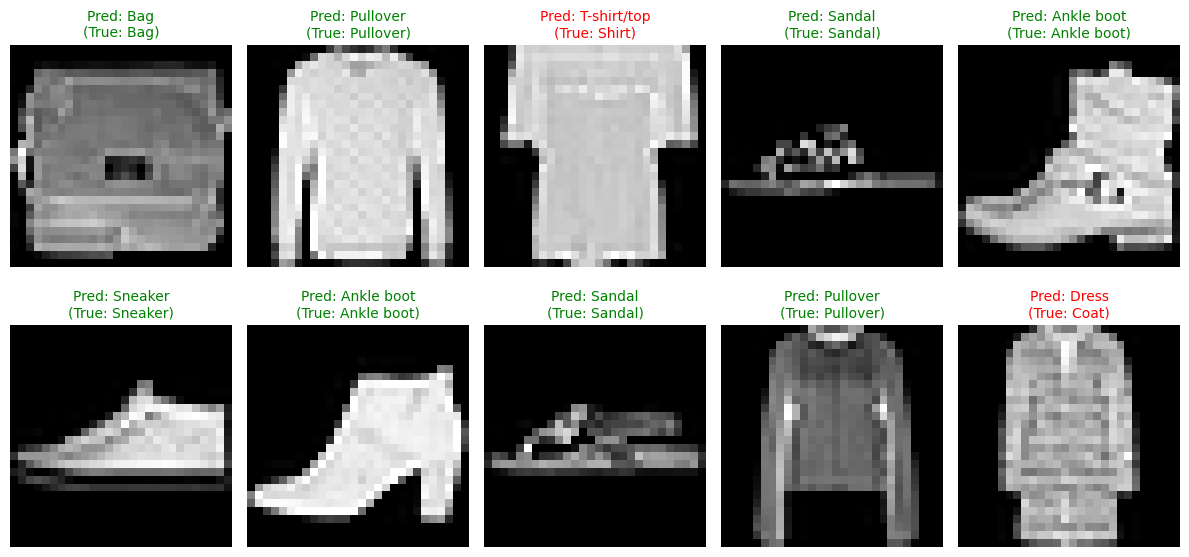

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 테스트 데이터 중 무작위로 10개의 샘플 선택
random_indices = np.random.choice(len(x_test), 10, replace=False)
sample_images = x_test[random_indices]
sample_labels = y_test[random_indices]

# 2. 모델을 통한 예측 수행
predictions = model.predict(sample_images)
predicted_labels = np.argmax(predictions, axis=1)

# 3. 2행 5열의 그리드로 이미지와 예측 결과 시각화
plt.figure(figsize=(12, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(sample_images[i], cmap='gray')

    pred_class = class_names[predicted_labels[i]]
    true_class = class_names[sample_labels[i]]

    # 예측값과 정답이 일치하면 초록색, 틀리면 빨간색으로 표시
    color = 'green' if predicted_labels[i] == sample_labels[i] else 'red'

    plt.title(f"Pred: {pred_class}\n(True: {true_class})", color=color, fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()